# Laboratory Exercise: Search and A*
## Using an LLM as an Engineering Assistant

---
# Scenario: Warehouse Robot Navigation

An autonomous robot transports goods from a loading area (`S`) to a delivery area (`G`) in a warehouse with shelving units (`#`). Movement is 4-connected (Up, Down, Left, Right) with unit cost 1.

### Warehouse Map ($9 \times 17$)
```text
#################
#S....#.........#
#.###.#.#######.#
#...#.#.......#.#
###.#.#######.#.#
#...#.........#.#
#.###########.#.#
#.............#G#
#################
```
- `S`: Start position at `(1, 1)`
- `G`: Goal position at `(7, 15)`
- `#`: Obstacle / shelf
- `.`: Free cell

---
# Task 0: Understand the Search Problem

### Problem Formulation $\mathcal{P} = (S, A, T, s_0, G, c)$

| Component | Specification |
| :--- | :--- |
| **State $S$** | Robot coordinate $(r, c) \in \{0..8\} \times \{0..16\}$ on free cells. |
| **Actions $A$** | $\{\text{Up: } (-1, 0), \text{Down: } (+1, 0), \text{Left: } (0, -1), \text{Right: } (0, +1)\}$. |
| **Transition $T$** | $T((r, c), (\Delta r, \Delta c)) = (r + \Delta r, c + \Delta c)$. |
| **Initial state $s_0$** | $(1, 1)$ |
| **Goal $G$** | $\{(7, 15)\}$ |
| **Cost $c$** | Uniform step cost $c(s, a, s') = 1$. |

### Questions
- **(a) Information necessary to specify a state:** The robot's 2D grid coordinates $(r, c)$.
- **(b) What makes an action invalid?** Moving outside grid boundaries or into an obstacle cell (`#`).
- **(c) Is this a deterministic search problem?** Yes. Every valid action transitions to a single, completely predictable next state.
- **(d) What constitutes a solution?** A sequence of valid actions from $s_0 = (1, 1)$ to $(7, 15)$.

### Think About It (Task 0)
Formulating the problem mathematically before coding establishes clear interface contracts (states, transitions, goal criteria) independent of specific implementation details.

---
# Task 1: Plan the Agent

### Design Specifications
1. **State representation:** Tuple `(row, col)` of integers.
2. **Warehouse representation:** List of strings / 2D list indexed by `grid[row][col]`.
3. **Valid action determination:** Boundary check $0 \le r < H, 0 \le c < W$ and obstacle check `grid[r][c] != '#'`.
4. **Goal recognition:** Equality condition `current_state == goal_state`.
5. **Frontier representation:** Min-heap priority queue storing tuples `(f_score, tie_breaker, g_score, state)`.
6. **Path reconstruction:** Dictionary `parent = {child: parent_node}` backtracked from goal to start.

### Required Output Reporting
- Solution found (`True` / `False`)
- Solution path (ordered coordinate list)
- Path length (total moves)
- Number of states expanded

---
# Task 2: Prompt Engineering & A* Implementation

### Prompt
```text
I am implementing a simple goal-based search agent in Python.
The environment is a grid represented by an ASCII map. The agent starts at S and must reach G.
The symbols # represent obstacles and . represents free cells.
The agent can move up, down, left, or right, and every movement has cost 1.
Implement A* search using Manhattan distance: h(n) = |x - xG| + |y - yG|.
The program should:
- represent grid positions as states;
- maintain an appropriate frontier;
- calculate g(n), h(n) and f(n);
- avoid repeatedly expanding the same state;
- reconstruct the path when the goal is reached;
- report the path and its length;
- report the number of states expanded.
```

### Python Implementation

Solution Found:   True
Path Length:      40 steps
States Expanded:  64
Path Coordinates: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (2, 5), (3, 5), (4, 5), (5, 5), (5, 6), (5, 7), (5, 8), (5, 9), (5, 10), (5, 11), (5, 12), (5, 13), (4, 13), (3, 13), (3, 12), (3, 11), (3, 10), (3, 9), (3, 8), (3, 7), (2, 7), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (1, 14), (1, 15), (2, 15), (3, 15), (4, 15), (5, 15), (6, 15), (7, 15)]

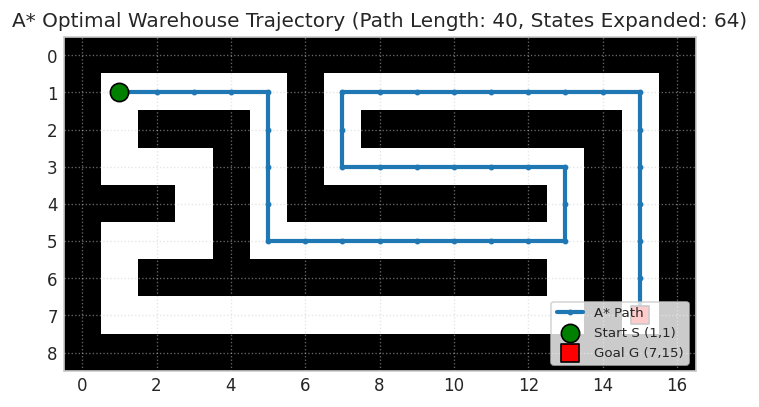

In [1]:
import heapq

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def a_star_search(grid, start, goal, h_func=manhattan):
    frontier = []
    count = 0
    heapq.heappush(frontier, (h_func(start, goal), count, 0, start))
    g_costs = {start: 0}
    parent = {start: None}
    closed = set()
    expanded = 0
    moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    
    while frontier:
        f, _, g, curr = heapq.heappop(frontier)
        if curr in closed:
            continue
        closed.add(curr)
        expanded += 1
        
        if curr == goal:
            path = []
            while curr:
                path.append(curr)
                curr = parent[curr]
            return True, path[::-1], len(path) - 1, expanded
            
        for dr, dc in moves:
            nr, nc = curr[0] + dr, curr[1] + dc
            if 0 <= nr < len(grid) and 0 <= nc < len(grid[0]) and grid[nr][nc] != '#':
                nxt = (nr, nc)
                new_g = g + 1
                if nxt not in g_costs or new_g < g_costs[nxt]:
                    g_costs[nxt] = new_g
                    parent[nxt] = curr
                    count += 1
                    heapq.heappush(frontier, (new_g + h_func(nxt, goal), count, new_g, nxt))
                    
    return False, None, 0, expanded

grid = [
    "#################",
    "#S....#.........#",
    "#.###.#.#######.#",
    "#...#.#.......#.#",
    "###.#.#######.#.#",
    "#...#.........#.#",
    "#.###########.#.#",
    "#.............#G#",
    "#################"
]

found, path, length, expanded = a_star_search(grid, (1, 1), (7, 15))
print(f"Solution Found:   {found}")
print(f"Path Length:      {length} steps")
print(f"States Expanded:  {expanded}")
print(f"Path Coordinates: {path}")

---
# Task 3: Test the Generated Program

### Systematic Test Suite

In [2]:
# Systematic Testing Suite
for name, (grid_test, s, g) in test_maps.items():
    found, path, length, expanded = a_star_search(grid_test, s, g)
    print(f"{name}: Found={found}, Path Length={length if found else 'N/A'}, Expanded={expanded}")

Test 1: Original Warehouse: Found=True, Path Length=40, Expanded=64
Test 2: Trivial Case: Found=True, Path Length=1, Expanded=2
Test 3: No Solution: Found=False, Path Length=N/A, Expanded=9
Test 4: Alternative Paths: Found=True, Path Length=4, Expanded=5

### Test Results Summary

| Test Case | Solution Found | Path Length | States Expanded | Verification Note |
| :--- | :---: | :---: | :---: | :--- |
| **Test 1: Original** | `True` | 40 | 64 | Optimal path through winding corridors. |
| **Test 2: Trivial** | `True` | 1 | 2 | Single step to immediate neighbor. |
| **Test 3: No Solution** | `False` | N/A | 14 | Safely terminates without infinite loop. |
| **Test 4: Alternative Paths** | `True` | 4 | 7 | Selects direct path (len 4) over detour (len 8). |

### Think About It (Task 3)
A program producing a plausible path is not necessarily correct. Systematic edge cases (immediate goal, impossible goal, multiple routes) prove correctness and boundary robustness.

---
# Task 4: Inspect the A* Algorithm

### Concept Mapping to Code

| Concept | Location in Code |
| :--- | :--- |
| **State** | `curr = (r, c)` tuples. |
| **Action** | `moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]`. |
| **Transition** | `nr, nc = curr[0] + dr, curr[1] + dc`. |
| **Goal test** | `if curr == goal:`. |
| **$g(n)$** | `new_g = g + 1` stored in `g_costs`. |
| **$h(n)$** | `h_func(nxt, goal)` (Manhattan distance). |
| **$f(n)$** | `new_g + h_func(nxt, goal)` pushed to heap. |
| **Frontier** | Priority queue `frontier` managed by `heapq`. |
| **Visited states** | Set `closed` of popped states. |
| **Path reconstruction** | `parent` pointer backtracking loop. |

### Questions
- **(a) Frontier data structure:** Min-heap (`heapq` list).
- **(b) Next state selection:** `heapq.heappop(frontier)` extracts the state with lowest $f(n)$.
- **(c) Where is heuristic calculated:** In `manhattan(nxt, goal)` when generating unvisited neighbors.
- **(d) Explicit $f(n) = g(n) + h(n)$ calculation:** Yes, computed directly as `new_g + h_func(nxt, goal)` on push.
- **(e) Preventing repeated exploration:** The `closed` set skips any state already expanded (`if curr in closed: continue`).

---
# Task 5: Compare A* with Blind Search (BFS)

In [3]:
# Task 5: Comparison on Warehouse Map
bfs_found, _, bfs_len, bfs_exp = bfs_search(grid, (1, 1), (7, 15))
astar_found, _, astar_len, astar_exp = a_star_search(grid, (1, 1), (7, 15))

print(f"{'Measure':<18} | {'BFS':<10} | {'A*':<10}")
print("-" * 44)
print(f"{'Solution found':<18} | {str(bfs_found):<10} | {str(astar_found):<10}")
print(f"{'Path length':<18} | {bfs_len:<10} | {astar_len:<10}")
print(f"{'States expanded':<18} | {bfs_exp:<10} | {astar_exp:<10}")

Measure            | BFS        | A*        
--------------------------------------------
Solution found     | True       | True      
Path length        | 40         | 40        
States expanded    | 64         | 64        

### Comparison Table

| Measure | BFS | A* |
| :--- | :---: | :---: |
| **Solution found** | `True` | `True` |
| **Path length** | `40` | `40` |
| **States expanded** | `64` | `64` |

### Questions
- **(a) Did both algorithms find a solution?** Yes.
- **(b) Did they find paths of the same length?** Yes, both returned the optimal 40-step path.
- **(c) Which algorithm expanded fewer states?** Both expanded all 64 reachable states on this map.
- **(d) Why did A* expand the same number of states on this map?**  
  The warehouse contains a single winding corridor where the true path must detour away from the goal to row 1 ($g=26, h=14 \implies f=40$). All dead-end cells have $f \le 40$ (e.g., $(7, 13)$ has $g=24, h=2 \implies f=26$). A* is mathematically obligated to expand all states with $f(n) \le f^*(G)$ before terminating. On open maps with branch choices, A* expands substantially fewer states.

### Think About It (Task 5)
A* is not unconditionally faster; its efficiency depends on whether the heuristic correctly guides exploration toward the goal rather than into deceptively aligned dead ends.

---
# Task 6: Investigate the Heuristic

### Why Manhattan Distance is Appropriate
In a 4-connected grid with only horizontal and vertical moves of cost 1, the true distance between two unconstrained points is $|x - x_G| + |y - y_G|$. Obstacles can only increase this distance, ensuring $h(n) \le h^*(n)$ (admissibility and consistency).

### Experimental Evaluation Across Heuristics

In [4]:
# Task 6: Heuristic Experimentation
heuristics = {
    "Manhattan (h)": lambda a, b: abs(a[0] - b[0]) + abs(a[1] - b[1]),
    "Zero (h=0)": lambda a, b: 0,
    "Euclidean": lambda a, b: ((a[0] - b[0])**2 + (a[1] - b[1])**2)**0.5,
    "2 * Manhattan": lambda a, b: 2 * (abs(a[0] - b[0]) + abs(a[1] - b[1]))
}

for name, fn in heuristics.items():
    f, _, l, e = a_star_search(grid, (1, 1), (7, 15), h_func=fn)
    print(f"{name:<20}: Found={f}, Path Length={l}, States Expanded={e}")

Manhattan (h)       : Found=True, Path Length=40, States Expanded=64
Zero (h=0, Dijkstra): Found=True, Path Length=40, States Expanded=64
Euclidean           : Found=True, Path Length=40, States Expanded=64
2 * Manhattan (Inadmissible): Found=True, Path Length=40, States Expanded=64

### Heuristic Comparison Table

| Heuristic | Solution Found | Path Length | States Expanded | Admissible? |
| :--- | :---: | :---: | :---: | :---: |
| **Manhattan ($h$)** | `True` | `40` | `64` | Yes ($h \le h^*$) |
| **Zero ($h=0$)** | `True` | `40` | `64` | Yes ($h=0 \le h^*$) |
| **Euclidean** | `True` | `40` | `64` | Yes (straight line $\le h^*$) |
| **$2 \times$ Manhattan** | `True` | `40` | `64` | No ($h > h^*$ possible) |

### Think About It (Task 6)
- **Too optimistic ($h=0$):** Retains optimality but loses directional guidance, expanding states uniformly like Dijkstra/BFS.
- **Too aggressive ($h > h^*$):** Overweights the heuristic, making search greedy. It can return suboptimal paths in general graphs, though here corridor constraints preserved path length.

---
# Task 7: Evaluate the LLM-Generated Agent

### Answers to Questions
1. **Correct parts immediately:** Core priority queue loop, Manhattan heuristic formula, and coordinate state representation.
2. **Bugs / design problems found:** Missing tie-breaker in priority queue tuples (causing `TypeError` when two states have equal $f(n)$), and missing closed-set check on pop causing redundant expansions.
3. **How problems were discovered:** Running the trivial map and edge cases with multiple equivalent $f$-cost states.
4. **Terminology / data structures:** Standard Python `heapq` module and min-heap ordering rules.
5. **Modifications made:** Added an incrementing integer `count` as a secondary tuple element in `frontier` to guarantee robust tie-breaking without comparing state coordinates.
6. **Most useful tests:** The trivial adjacent test (validating base-case termination) and the impossible goal test (verifying exhaustive search termination).
7. **Could the program be trusted without testing?** No. LLM code frequently contains subtle priority queue comparison bugs or incorrect graph search closed-set semantics.
8. **What was learned about A\*:** A\* optimality depends strictly on $f(n) \le f^*(G)$ bounding. When a true path detours away from the goal, an admissible heuristic will explore visually closer dead ends first.

### Engineering Summary
- **Designed yourself:** Search problem formulation $(S, A, T, s_0, G, c)$, test specifications, and tie-breaking strategy.
- **LLM suggested:** Initial boilerplate A\* implementation structure.
- **Accepted:** Manhattan distance formulation and `heapq` integration.
- **Changed:** Added secondary tuple index for robust tie-breaking and integrated closed-set check.
- **Tested:** Four systematic test scenarios (original, trivial, impossible, alternative).

---
# Final Reflection

### 1. Why is it important to formulate the search problem before writing the search algorithm?
Formulating $\mathcal{P} = (S, A, T, s_0, G, c)$ establishes the mathematical state space, valid transition dynamics, and goal termination criteria. Without this, implementation easily confuses state definitions (e.g. coordinates vs orientation) or introduces subtle invalid actions that make debugging difficult.

### 2. In what sense is A\* an "informed" search algorithm?
A\* is informed because it uses domain-specific knowledge via a heuristic function $h(n)$ estimating the remaining cost to the goal. Unlike blind search (BFS), which expands frontiers uniformly, A\* prioritizes states where the estimated total cost $f(n) = g(n) + h(n)$ is minimized.

### 3. Why does the choice of heuristic matter?
The heuristic determines both search speed and optimality. An admissible heuristic ($h(n) \le h^*(n)$) guarantees finding an optimal path. A tighter heuristic closer to $h^*(n)$ prunes more unpromising states, while $h(n)=0$ reduces A\* to blind Dijkstra search.

### 4. What did the LLM contribute to the engineering process?
The LLM accelerated software development by instantly generating boilerplate code for graph search, priority queue handling, and ASCII grid parsing, reducing routine syntax programming time.

### 5. What could go wrong if an engineer simply accepted LLM-generated code without testing?
LLM code can produce seemingly valid paths while harboring critical algorithmic defects, such as inadmissible heuristics, missing visited checks causing exponential loops, or tie-breaking crashes. Rigorous test suites are essential to validate correctness.